# ENEM 2020: visões sobre as notas

Este notebook lê o modelo dimensional carregado no MySQL e gera as visões pedidas no teste. Cada gráfico é salvo em `docs/img/` e aparece no README.

- **Nota como indicador**: a média das quatro provas objetivas por participante (ADR-0006), só para quem esteve presente nas quatro.
- **Médias e medianas por grupo** usam todos os participantes presentes nas quatro provas. A média é sempre azul e a mediana, vermelha. Nas barras, a marca vermelha sobre a barra é a mediana, e os dois valores ficam na coluna à direita. Nas linhas, a azul com bolinhas é a média e a vermelha com quadrados é a mediana. A linha cinza escura é a referência de comparação. Quando a média fica acima da mediana, um grupo menor de notas altas puxa a média para cima.
- **Distribuições e correlações** usam uma amostra determinística de cerca de 10% dos participantes presentes nas quatro provas (`CRC32(nu_inscricao) % 10 = 0`). A amostra é a mesma a cada execução.

Para executar: `docker compose run --rm app jupyter nbconvert --to notebook --execute --inplace notebooks/analise_enem_2020.ipynb`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymysql
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.etl.load import conectar  # noqa: E402

PASTA_IMG = RAIZ / "docs" / "img"
PASTA_IMG.mkdir(parents=True, exist_ok=True)

# Paleta e tinta validadas para leitura com daltonismo (fundo claro)
SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
TINTA_SUAVE = "#898781"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # azul, laranja, aqua, amarelo
AZUL = SERIES[0]
DIVERGENTE = LinearSegmentedColormap.from_list(
    "divergente", ["#e34948", "#f0efec", "#2a78d6"]
)  # vermelho (negativo), cinza neutro, azul (positivo)

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "figure.dpi": 110, "savefig.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 11,
    "text.color": TINTA, "axes.labelcolor": TINTA_SECUNDARIA,
    "axes.titlesize": 13.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 30,  # espaço para o subtítulo entre o título e o gráfico
    "axes.titlecolor": TINTA, "axes.edgecolor": EIXO,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "xtick.labelcolor": TINTA_SECUNDARIA, "ytick.labelcolor": TINTA_SECUNDARIA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
})


def consultar(sql: str) -> pd.DataFrame:
    """Executa uma consulta no MySQL e devolve um DataFrame."""
    conexao = conectar()
    try:
        with conexao.cursor() as cursor:
            cursor.execute(sql)
            colunas = [c[0] for c in cursor.description]
            df = pd.DataFrame(cursor.fetchall(), columns=colunas)
    finally:
        conexao.close()
    # Decimal do MySQL vira float para os cálculos
    for coluna in df.columns:
        if df[coluna].dtype == object and len(df) and type(df[coluna].iloc[0]).__name__ == "Decimal":
            df[coluna] = df[coluna].astype(float)
    return df


def consultar_grande(sql: str, lote: int = 500_000) -> pd.DataFrame:
    """Lê uma consulta grande em lotes, sem trazer tudo para a memória de uma vez."""
    conexao = conectar()
    partes = []
    try:
        with conexao.cursor(pymysql.cursors.SSCursor) as cursor:
            cursor.execute(sql)
            colunas = [c[0] for c in cursor.description]
            while linhas := cursor.fetchmany(lote):
                partes.append(pd.DataFrame(linhas, columns=colunas))
    finally:
        conexao.close()
    return pd.concat(partes, ignore_index=True)


def agregar(df: pd.DataFrame, grupo, valor: str = "media") -> pd.DataFrame:
    """Número de participantes, média e mediana de `valor` por grupo."""
    return df.groupby(grupo, observed=True)[valor].agg(
        participantes="size", media="mean", mediana="median"
    ).reset_index()


# Cores fixas em todos os gráficos: média em azul, mediana em vermelho e
# linha de referência em cinza escuro (par validado para daltonismo)
COR_MEDIANA = "#e34948"
COR_REFERENCIA = TINTA_SECUNDARIA
FONTE_VALOR = 10

LEGENDA_BARRAS = [Patch(color=AZUL, label="Média"),
                  Line2D([], [], color=COR_MEDIANA, marker="|", linestyle="", markersize=13,
                         markeredgewidth=2.4, label="Mediana")]


def rotulo_par(media: float, mediana: float, separador: str = " | ") -> str:
    """Texto padrão com os dois valores, sempre juntos e na mesma ordem."""
    return f"média {num(media)}{separador}mediana {num(mediana)}"


def legenda_referencia(nome: str) -> Line2D:
    """Item de legenda da linha de referência."""
    return Line2D([], [], color=COR_REFERENCIA, linewidth=3, label=f"{nome} (referência)")


def legenda_abaixo(ax, itens, distancia: float = -0.08) -> None:
    """Legenda centralizada embaixo do gráfico, fora da área dos dados."""
    ax.legend(handles=itens, loc="upper center", bbox_to_anchor=(0.5, distancia),
              ncols=len(itens), fontsize=10, handlelength=1.6, columnspacing=1.6)


ALTURA_BARRA = 0.62
ESPACO_TOPO_PT = 30  # espaço, em pontos, acima da barra de cima para cabeçalho e rótulo


def topo_das_barras(n: int) -> float:
    """Posição vertical (em dados) da borda de cima da barra mais alta."""
    return n - 1 + ALTURA_BARRA / 2


def reservar_topo(ax, n: int) -> None:
    """Ajusta o limite vertical para sobrar um espaço fixo, em pontos, acima das barras.

    O espaço não depende de quantas barras o painel tem, então o cabeçalho e o
    rótulo da referência ficam sempre à mesma distância da barra de cima.
    """
    fig = ax.figure
    fig.tight_layout()
    fig.canvas.draw()
    altura_px = ax.get_window_extent().height
    espaco_px = ESPACO_TOPO_PT * fig.dpi / 72
    base = -0.6
    folga = espaco_px * (topo_das_barras(n) - base) / max(altura_px - espaco_px, 1)
    ax.set_ylim(base, topo_das_barras(n) + folga)


def barras_com_mediana(ax, rotulos, medias, medianas) -> None:
    """Desenha a média em barras horizontais e a mediana como uma marca sobre cada barra.

    Os valores ficam numa coluna fixa à direita da área do gráfico, com
    cabeçalho "média | mediana". Assim nenhuma linha de referência cruza o texto.
    """
    rotulos, medias, medianas = list(rotulos), list(medias), list(medianas)
    n = len(rotulos)
    ax.barh(range(n), medias, color=AZUL, height=ALTURA_BARRA)
    ax.scatter(medianas, range(n), marker="|", s=320, linewidths=2.8, color=COR_MEDIANA, zorder=4)
    ax.set_yticks(range(n), rotulos)
    ax.tick_params(axis="y", labelsize=11, labelcolor=TINTA, length=0)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    reservar_topo(ax, n)
    # Coluna de valores: posição horizontal fixa logo depois da borda direita do gráfico
    valores = ([(i, num(m), 52, "right", TINTA) for i, m in enumerate(medias)]
               + [(i, "|", 60, "center", TINTA_SUAVE) for i in range(n)]
               + [(i, num(md), 68, "left", TINTA) for i, md in enumerate(medianas)])
    for y, texto, deslocamento, alinhamento, cor in valores:
        ax.annotate(texto, (1, y), xycoords=("axes fraction", "data"), xytext=(deslocamento, 0),
                    textcoords="offset points", ha=alinhamento, va="center", fontsize=FONTE_VALOR,
                    color=cor, annotation_clip=False)
    # Cabeçalho da coluna, sempre à mesma distância da barra de cima
    for texto, deslocamento, alinhamento in [("média", 52, "right"), ("mediana", 68, "left")]:
        ax.annotate(texto, (1, topo_das_barras(n)), xycoords=("axes fraction", "data"),
                    xytext=(deslocamento, 8), textcoords="offset points", ha=alinhamento, va="bottom",
                    fontsize=FONTE_VALOR, fontweight="bold", color=TINTA_SECUNDARIA, annotation_clip=False)


def linha_referencia(ax, valor: float, nome: str, n_barras: int) -> None:
    """Linha vertical de referência, sólida e cinza escuro, com o nome escrito acima dela.

    A linha vai até a borda de cima das barras. O nome fica logo acima da ponta,
    alinhado pela direita na linha, para não encostar na coluna de valores.
    """
    topo = topo_das_barras(n_barras)
    ax.vlines(valor, -0.6, topo, color=COR_REFERENCIA, linewidth=3, zorder=3)
    ax.annotate(f"{nome} {num(valor)}", (valor, topo), xytext=(2, 8), textcoords="offset points",
                ha="right", va="bottom", fontsize=FONTE_VALOR, fontweight="bold", color=TINTA,
                annotation_clip=False)


def linha_com_mediana(ax, x, medias, medianas,
                      rotulo_inicio: str = "above", rotulo_fim: str = "above") -> None:
    """Desenha a média em azul com bolinhas e a mediana em vermelho com quadrados.

    Cor e marcador diferentes separam as duas séries também para quem tem
    daltonismo. As duas pontas recebem o rótulo com os dois valores.
    `rotulo_inicio` e `rotulo_fim` dizem se cada rótulo fica acima ("above")
    ou abaixo ("below") dos pontos.
    """
    x, medias, medianas = list(x), list(medias), list(medianas)
    ax.plot(x, medias, color=AZUL, linewidth=2.4, marker="o", markersize=6, label="Média")
    ax.plot(x, medianas, color=COR_MEDIANA, linewidth=2.4, marker="s", markersize=5.5, label="Mediana")
    for indice, lado, alinhamento in [(0, rotulo_inicio, "left"), (-1, rotulo_fim, "right")]:
        acima = lado == "above"
        y = max(medias[indice], medianas[indice]) if acima else min(medias[indice], medianas[indice])
        ax.annotate(rotulo_par(medias[indice], medianas[indice], separador="\n"), (x[indice], y),
                    xytext=(0, 8 if acima else -8), textcoords="offset points",
                    ha=alinhamento, va="bottom" if acima else "top", fontsize=FONTE_VALOR, color=TINTA)


def num(valor: float, casas: int = 1) -> str:
    """Formata número no padrão brasileiro (vírgula decimal, ponto de milhar)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def salvar(fig, nome: str, titulo: str, texto: str) -> None:
    """Salva o gráfico em docs/img com o título no topo da figura.

    O título diz a conclusão do gráfico, para o leitor entender de relance, e o
    texto logo abaixo diz o que está sendo medido. Os dois ficam acima de tudo,
    numa distância fixa em pontos, qualquer que seja a altura da figura.
    """
    fig.tight_layout()
    topo = fig.transFigure
    fig.text(0.01, 1, titulo, transform=offset_copy(topo, fig=fig, y=26, units="points"),
             fontsize=14.5, fontweight="bold", color=TINTA, va="bottom")
    fig.text(0.01, 1, texto, transform=offset_copy(topo, fig=fig, y=8, units="points"),
             fontsize=10.5, color=TINTA_SECUNDARIA, va="bottom")
    fig.savefig(PASTA_IMG / f"{nome}.png", bbox_inches="tight", pad_inches=0.3)
    plt.show()


def subtitulo(ax, texto: str) -> None:
    """Escreve uma linha de contexto abaixo do título do gráfico."""
    ax.text(0, 1.015, texto, transform=ax.transAxes, color=TINTA_SECUNDARIA, fontsize=10.5, va="bottom")


PROVAS = {"nu_nota_cn": "Ciências da Natureza", "nu_nota_ch": "Ciências Humanas",
          "nu_nota_lc": "Linguagens e Códigos", "nu_nota_mt": "Matemática"}

In [2]:
amostra = consultar("""
    SELECT f.nu_nota_cn, f.nu_nota_ch, f.nu_nota_lc, f.nu_nota_mt, f.nu_nota_redacao,
           f.nu_nota_comp1, f.nu_nota_comp2, f.nu_nota_comp3, f.nu_nota_comp4, f.nu_nota_comp5,
           f.nu_media_objetivas AS media, f.tp_status_redacao,
           p.tp_faixa_etaria, p.ds_sexo, p.ds_cor_raca, p.ds_escola, p.ds_treineiro,
           e.ds_dependencia_adm_esc, e.ds_localizacao_esc, l.sg_uf_prova,
           q.q001, q.q002, q.q005, q.q006, q.q008, q.q010, q.q024, q.q025
    FROM fato_participacao f
    JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    JOIN dim_escola e ON e.sk_escola = f.sk_escola
    JOIN dim_local_prova l ON l.sk_local_prova = f.sk_local_prova
    JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL
      AND CRC32(f.nu_inscricao) % 10 = 0
""")
print(f"Amostra: {len(amostra):,} participantes presentes nas quatro provas")

Amostra: 258,587 participantes presentes nas quatro provas


In [3]:
# Base completa dos presentes nas quatro provas, com os atributos usados nos
# agrupamentos. Média e mediana por grupo saem desta mesma base.
base = consultar_grande("""
    SELECT CAST(f.nu_media_objetivas AS DOUBLE) AS media, f.tp_status_redacao,
           p.tp_faixa_etaria, p.ds_faixa_etaria, p.ds_sexo, p.ds_cor_raca, p.ds_escola,
           e.ds_dependencia_adm_esc, l.sg_uf_prova, q.q002, q.q006, q.q024, q.q025
    FROM fato_participacao f
    JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    JOIN dim_escola e ON e.sk_escola = f.sk_escola
    JOIN dim_local_prova l ON l.sk_local_prova = f.sk_local_prova
    JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL
""")
for coluna in base.columns.drop("media"):
    base[coluna] = base[coluna].astype("category")
geral = base["media"].mean()
mediana_geral = base["media"].median()
print(f"Base completa: {len(base):,} participantes. Média {geral:.2f}, mediana {mediana_geral:.2f}")

Base completa: 2,588,681 participantes. Média 512.89, mediana 503.93


## 1. A nota como indicador de desempenho

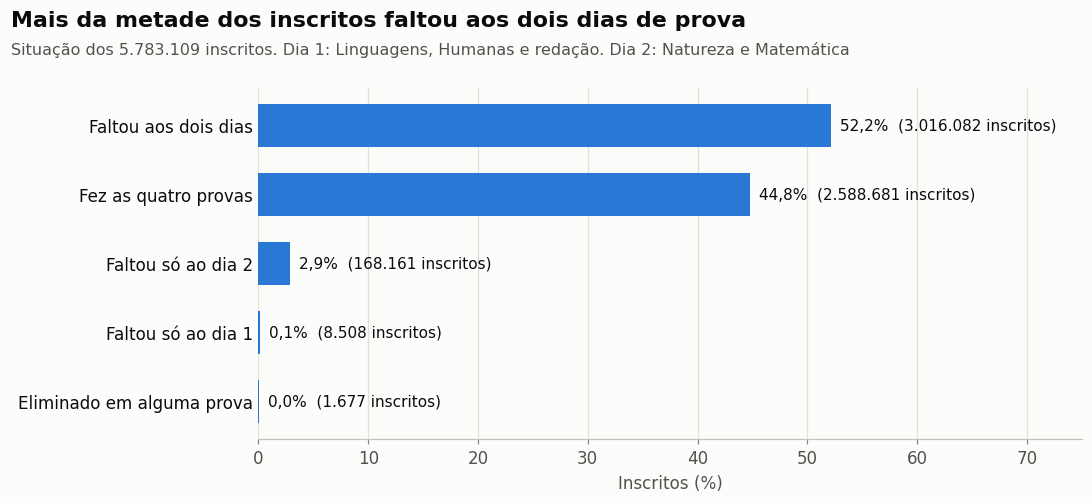

In [4]:
situacao = consultar("""
    SELECT CASE
             WHEN tp_presenca_cn = 1 AND tp_presenca_ch = 1
                  AND tp_presenca_lc = 1 AND tp_presenca_mt = 1 THEN 'Fez as quatro provas'
             WHEN (tp_presenca_lc = 0 OR tp_presenca_ch = 0)
                  AND (tp_presenca_cn = 0 OR tp_presenca_mt = 0) THEN 'Faltou aos dois dias'
             WHEN tp_presenca_lc = 0 OR tp_presenca_ch = 0 THEN 'Faltou só ao dia 1'
             WHEN tp_presenca_cn = 0 OR tp_presenca_mt = 0 THEN 'Faltou só ao dia 2'
             ELSE 'Eliminado em alguma prova'
           END AS situacao,
           COUNT(*) AS inscritos
    FROM fato_participacao
    GROUP BY situacao
""")
situacao["pct"] = 100 * situacao["inscritos"] / situacao["inscritos"].sum()
situacao = situacao.sort_values("inscritos").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(situacao["situacao"], situacao["pct"], color=AZUL, height=0.62)
for i, (pct, n) in enumerate(zip(situacao["pct"], situacao["inscritos"])):
    ax.text(pct + 0.8, i, f"{num(pct)}%  ({num(n, 0)} inscritos)", va="center", fontsize=FONTE_VALOR)
ax.tick_params(axis="y", labelsize=11, labelcolor=TINTA, length=0)
ax.set_xlim(0, 75)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Inscritos (%)")
salvar(fig, "13_situacao_inscritos",
       "Mais da metade dos inscritos faltou aos dois dias de prova",
       f"Situação dos {num(situacao['inscritos'].sum(), 0)} inscritos. "
       "Dia 1: Linguagens, Humanas e redação. Dia 2: Natureza e Matemática")

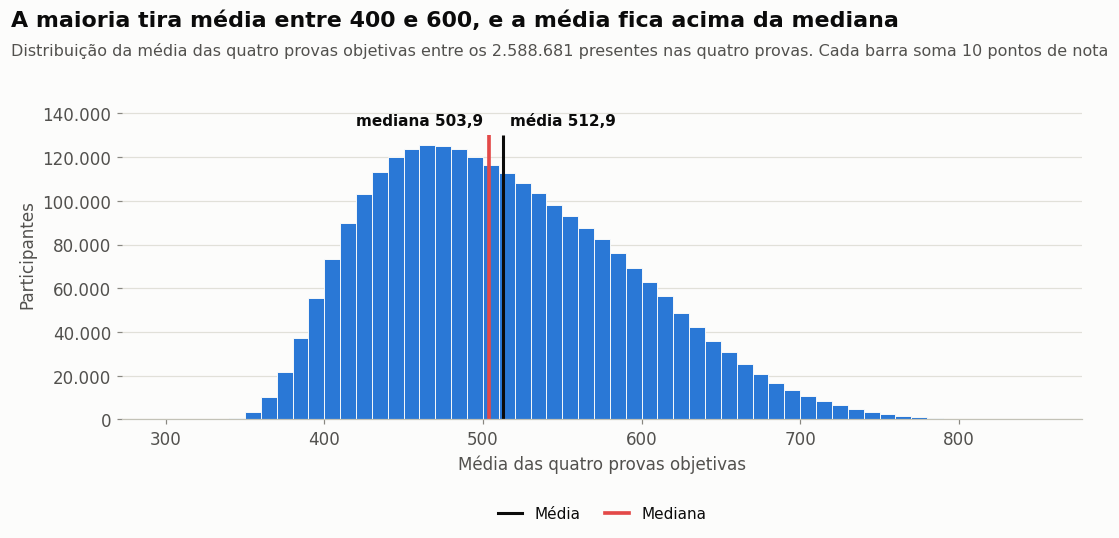

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(base["media"], bins=np.arange(300, 860, 10), color=AZUL, edgecolor=SUPERFICIE, linewidth=0.6)
topo = ax.get_ylim()[1] * 1.15  # espaço acima das barras para os rótulos das linhas
ax.set_ylim(0, topo)
ax.vlines(geral, 0, topo * 0.86, color=TINTA, linewidth=2)
ax.text(geral + 4, topo * 0.88, f"média {num(geral)}", fontsize=FONTE_VALOR, fontweight="bold", va="bottom")
ax.vlines(mediana_geral, 0, topo * 0.86, color=COR_MEDIANA, linewidth=2.4)
ax.text(mediana_geral - 4, topo * 0.88, f"mediana {num(mediana_geral)}", fontsize=FONTE_VALOR,
        fontweight="bold", va="bottom", ha="right")
ax.set_xlabel("Média das quatro provas objetivas")
ax.set_ylabel("Participantes")
ax.yaxis.set_major_formatter(lambda v, _: num(v, 0))
legenda_abaixo(ax, [Line2D([], [], color=TINTA, linewidth=2, label="Média"),
                    Line2D([], [], color=COR_MEDIANA, linewidth=2.4, label="Mediana")], distancia=-0.22)
salvar(fig, "01_distribuicao_media",
       "A maioria tira média entre 400 e 600, e a média fica acima da mediana",
       f"Distribuição da média das quatro provas objetivas entre os {num(len(base), 0)} presentes "
       "nas quatro provas. Cada barra soma 10 pontos de nota")

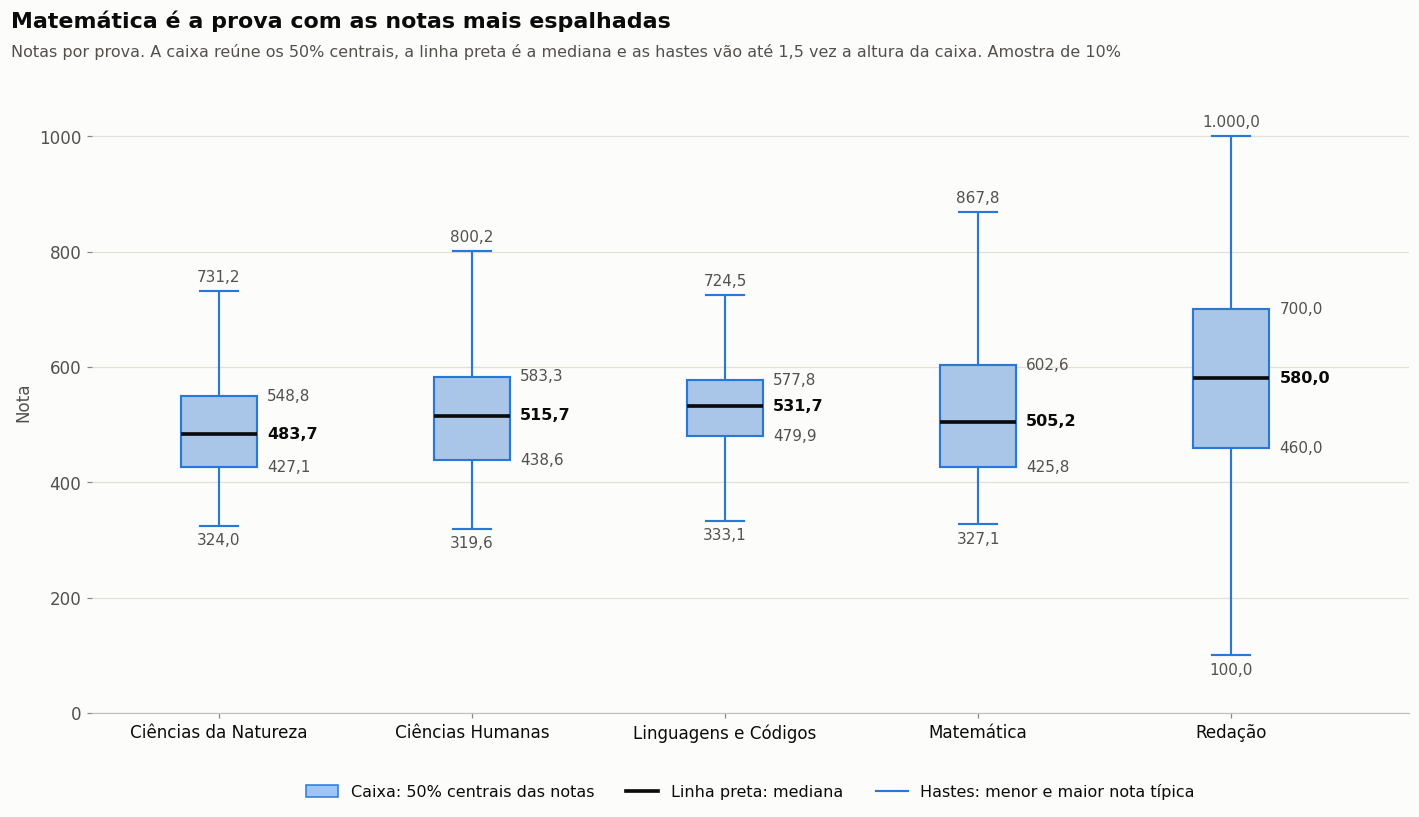

In [6]:
longo = amostra.melt(value_vars=list(PROVAS) + ["nu_nota_redacao"], var_name="prova", value_name="nota")
longo["prova"] = longo["prova"].map({**PROVAS, "nu_nota_redacao": "Redação"})
ordem = ["Ciências da Natureza", "Ciências Humanas", "Linguagens e Códigos", "Matemática", "Redação"]
CAIXA = "#9ec5f4"
fig, ax = plt.subplots(figsize=(13, 6.8))
sns.boxplot(data=longo, x="prova", y="nota", order=ordem, color=CAIXA, width=0.3, fliersize=0,
            linewidth=1.4, medianprops={"color": TINTA, "linewidth": 2.4},
            boxprops={"edgecolor": AZUL}, whiskerprops={"color": AZUL}, capprops={"color": AZUL}, ax=ax)
# Só os números: o significado de cada posição fica na legenda, uma vez
quartis = longo.groupby("prova")["nota"].quantile([0.25, 0.5, 0.75]).unstack()
for i, prova in enumerate(ordem):
    notas_prova = longo.loc[longo["prova"] == prova, "nota"]
    q1, mediana_prova, q3 = quartis.loc[prova, [0.25, 0.5, 0.75]]
    # Pontas das hastes como no seaborn: nota mais extrema dentro de 1,5 vez a altura da caixa
    haste_baixo = notas_prova[notas_prova >= q1 - 1.5 * (q3 - q1)].min()
    haste_cima = notas_prova[notas_prova <= q3 + 1.5 * (q3 - q1)].max()
    ax.text(i + 0.19, q3, num(q3), va="center", fontsize=FONTE_VALOR, color=TINTA_SECUNDARIA)
    ax.text(i + 0.19, mediana_prova, num(mediana_prova), va="center", fontsize=FONTE_VALOR + 0.5,
            fontweight="bold", color=TINTA)
    ax.text(i + 0.19, q1, num(q1), va="center", fontsize=FONTE_VALOR, color=TINTA_SECUNDARIA)
    ax.text(i, haste_cima + 12, num(haste_cima), ha="center", va="bottom", fontsize=FONTE_VALOR,
            color=TINTA_SECUNDARIA)
    ax.text(i, haste_baixo - 12, num(haste_baixo), ha="center", va="top", fontsize=FONTE_VALOR,
            color=TINTA_SECUNDARIA)
ax.set_xticks(range(len(ordem)), ordem)
ax.tick_params(axis="x", labelsize=11, labelcolor=TINTA)
ax.set_xlim(-0.5, len(ordem) - 0.3)
ax.set_ylim(0, 1080)
ax.set_xlabel("")
ax.set_ylabel("Nota")
# Legenda única que explica como ler o boxplot
ax.legend(handles=[
    Patch(facecolor=CAIXA, edgecolor=AZUL, label="Caixa: 50% centrais das notas"),
    Line2D([], [], color=TINTA, linewidth=2.4, label="Linha preta: mediana"),
    Line2D([], [], color=AZUL, linewidth=1.4, marker="_", markersize=14,
           label="Hastes: menor e maior nota típica"),
], loc="upper center", bbox_to_anchor=(0.5, -0.09), ncols=3, fontsize=10.5)
salvar(fig, "02_notas_por_prova",
       "Matemática é a prova com as notas mais espalhadas",
       "Notas por prova. A caixa reúne os 50% centrais, a linha preta é a mediana e as hastes vão até "
       "1,5 vez a altura da caixa. Amostra de 10%")

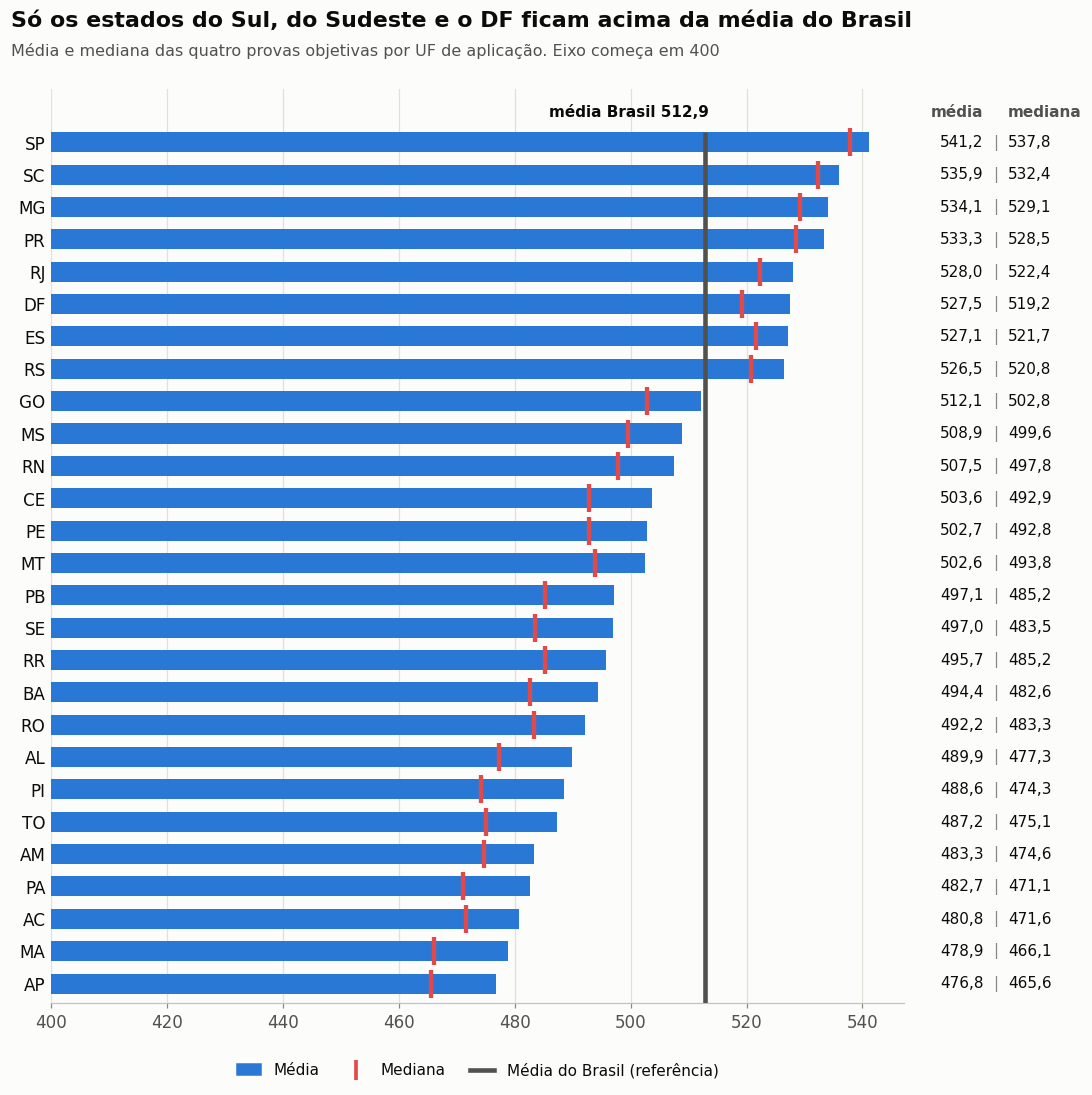

In [7]:
por_uf = agregar(base, "sg_uf_prova").sort_values("media")
fig, ax = plt.subplots(figsize=(10, 9.4))
barras_com_mediana(ax, por_uf["sg_uf_prova"].astype(str), por_uf["media"], por_uf["mediana"])
linha_referencia(ax, geral, "média Brasil", len(por_uf))
ax.set_xlim(400, por_uf["media"].max() + 6)
legenda_abaixo(ax, LEGENDA_BARRAS + [legenda_referencia("Média do Brasil")], distancia=-0.05)
salvar(fig, "03_media_por_uf",
       "Só os estados do Sul, do Sudeste e o DF ficam acima da média do Brasil",
       "Média e mediana das quatro provas objetivas por UF de aplicação. Eixo começa em 400")

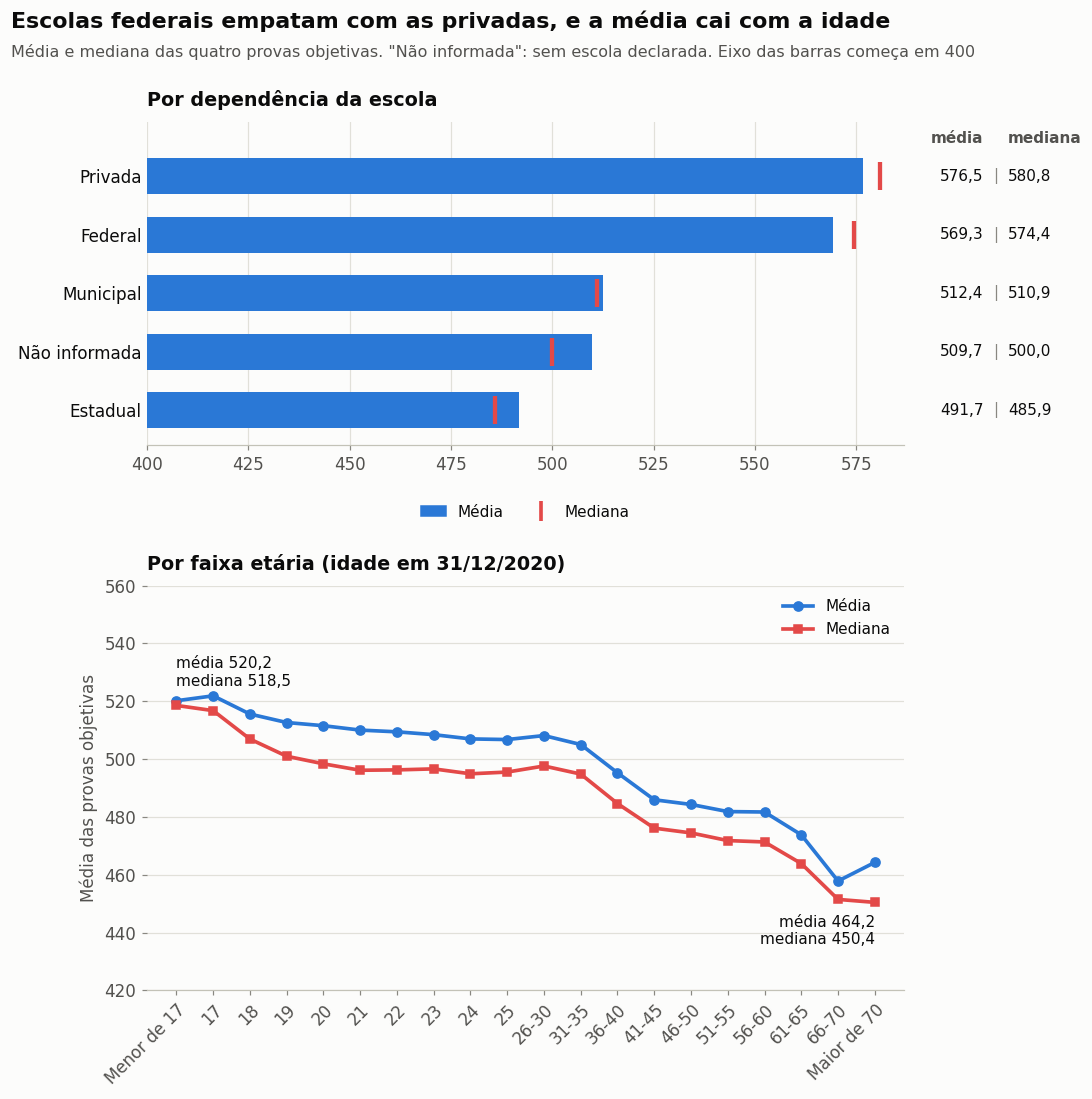

In [8]:
por_dependencia = agregar(base, "ds_dependencia_adm_esc").sort_values("media").reset_index(drop=True)
por_faixa = agregar(base[base["tp_faixa_etaria"].astype(int) > 0], ["tp_faixa_etaria", "ds_faixa_etaria"]) \
    .sort_values("tp_faixa_etaria")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9.4), gridspec_kw={"height_ratios": [1, 1.25]})
barras_com_mediana(ax1, por_dependencia["ds_dependencia_adm_esc"].astype(str), por_dependencia["media"],
                   por_dependencia["mediana"])
ax1.set_xlim(400, por_dependencia[["media", "mediana"]].max().max() + 6)
ax1.set_title("Por dependência da escola", fontsize=12.5, pad=10)
legenda_abaixo(ax1, LEGENDA_BARRAS, distancia=-0.14)
rotulos = por_faixa["ds_faixa_etaria"].astype(str).str.replace("Entre ", "") \
    .str.replace(" anos", "").str.replace(" e ", "-")
posicoes = range(len(rotulos))
linha_com_mediana(ax2, posicoes, por_faixa["media"], por_faixa["mediana"],
                  rotulo_inicio="above", rotulo_fim="below")
ax2.set_xticks(posicoes, rotulos)
ax2.set_xlim(-0.8, len(rotulos) - 0.2)
ax2.legend(loc="upper right", fontsize=10)
ax2.set_title("Por faixa etária (idade em 31/12/2020)", fontsize=12.5, pad=10)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax2.set_ylim(420, 560)
ax2.set_ylabel("Média das provas objetivas")
salvar(fig, "04_media_dependencia_faixa",
       "Escolas federais empatam com as privadas, e a média cai com a idade",
       "Média e mediana das quatro provas objetivas. \"Não informada\": sem escola declarada. "
       "Eixo das barras começa em 400")

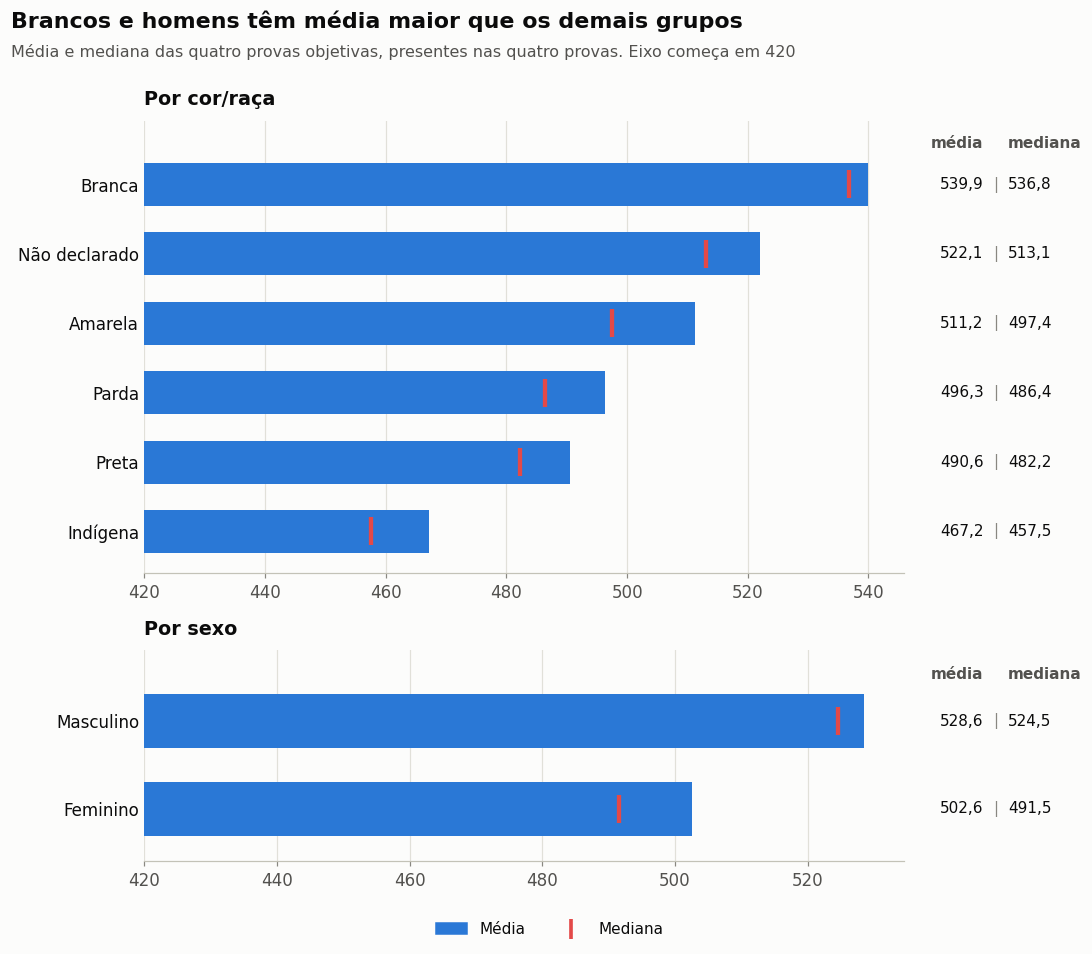

In [9]:
cor_raca = agregar(base, "ds_cor_raca").sort_values("media")
sexo = agregar(base, "ds_sexo").sort_values("media")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.6), gridspec_kw={"height_ratios": [6, 2.8]})
for ax, dados, coluna, titulo in [(ax1, cor_raca, "ds_cor_raca", "Por cor/raça"),
                                  (ax2, sexo, "ds_sexo", "Por sexo")]:
    ax.set_xlim(420, dados[["media", "mediana"]].max().max() + 6)
    barras_com_mediana(ax, dados[coluna].astype(str), dados["media"], dados["mediana"])
    ax.set_title(titulo, fontsize=12.5, pad=10)
fig.legend(handles=LEGENDA_BARRAS, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncols=2, fontsize=10)
salvar(fig, "14_media_cor_raca_sexo",
       "Brancos e homens têm média maior que os demais grupos",
       "Média e mediana das quatro provas objetivas, presentes nas quatro provas. Eixo começa em 420")

## 2. Correlação das variáveis com as notas

Spearman mede associação monotônica e serve para variáveis ordinais, como faixa de renda e escolaridade. As respostas "Não sei" (H em Q001 e Q002) ficam de fora. Para variáveis sem ordem (sexo, cor/raça, UF), a medida é o eta², a fração da variância da média explicada pelo grupo. A renda entra no gráfico de eta² como referência de comparação, mesmo sendo ordinal.

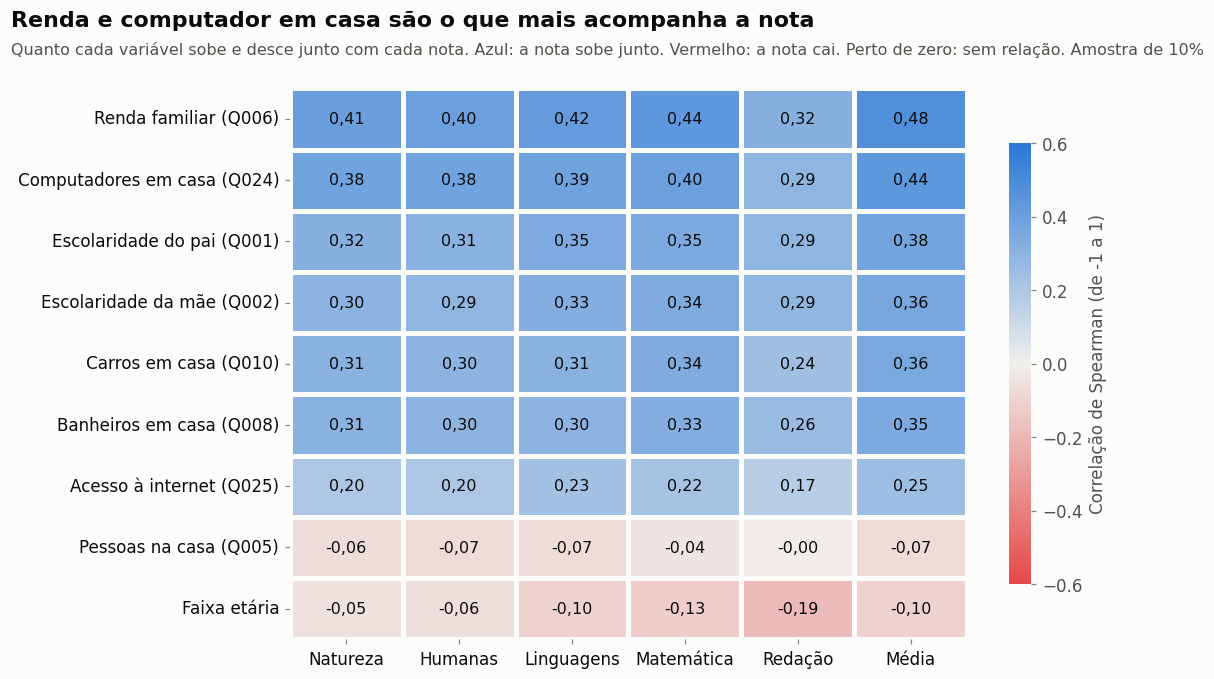

In [10]:
ordinal = pd.DataFrame({
    "Renda familiar (Q006)": amostra["q006"].map({c: i for i, c in enumerate("ABCDEFGHIJKLMNOPQ")}),
    "Escolaridade do pai (Q001)": amostra["q001"].map({c: i for i, c in enumerate("ABCDEFG")}),
    "Escolaridade da mãe (Q002)": amostra["q002"].map({c: i for i, c in enumerate("ABCDEFG")}),
    "Computadores em casa (Q024)": amostra["q024"].map({c: i for i, c in enumerate("ABCDE")}),
    "Acesso à internet (Q025)": amostra["q025"].map({"A": 0, "B": 1}),
    "Banheiros em casa (Q008)": amostra["q008"].map({c: i for i, c in enumerate("ABCDE")}),
    "Carros em casa (Q010)": amostra["q010"].map({c: i for i, c in enumerate("ABCDE")}),
    "Pessoas na casa (Q005)": amostra["q005"],
    "Faixa etária": amostra["tp_faixa_etaria"],
})
notas = amostra[list(PROVAS) + ["nu_nota_redacao", "media"]].rename(columns={
    "nu_nota_cn": "Natureza", "nu_nota_ch": "Humanas", "nu_nota_lc": "Linguagens",
    "nu_nota_mt": "Matemática", "nu_nota_redacao": "Redação", "media": "Média",
})
correlacao = pd.DataFrame({
    coluna_nota: ordinal.corrwith(notas[coluna_nota], method="spearman") for coluna_nota in notas
}).sort_values("Média", ascending=False)

fig, ax = plt.subplots(figsize=(10.5, 5.6))
sns.heatmap(correlacao, annot=correlacao.map(lambda v: num(v, 2)), fmt="", cmap=DIVERGENTE,
            vmin=-0.6, vmax=0.6, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Spearman (de -1 a 1)", "shrink": 0.8},
            annot_kws={"fontsize": 10.5, "color": TINTA}, ax=ax)
ax.grid(False)
ax.tick_params(axis="x", labelrotation=0, labelcolor=TINTA, labelsize=11)
ax.tick_params(axis="y", labelcolor=TINTA, labelsize=11)
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "05_correlacao_spearman",
       "Renda e computador em casa são o que mais acompanha a nota",
       "Quanto cada variável sobe e desce junto com cada nota. Azul: a nota sobe junto. "
       "Vermelho: a nota cai. Perto de zero: sem relação. Amostra de 10%")

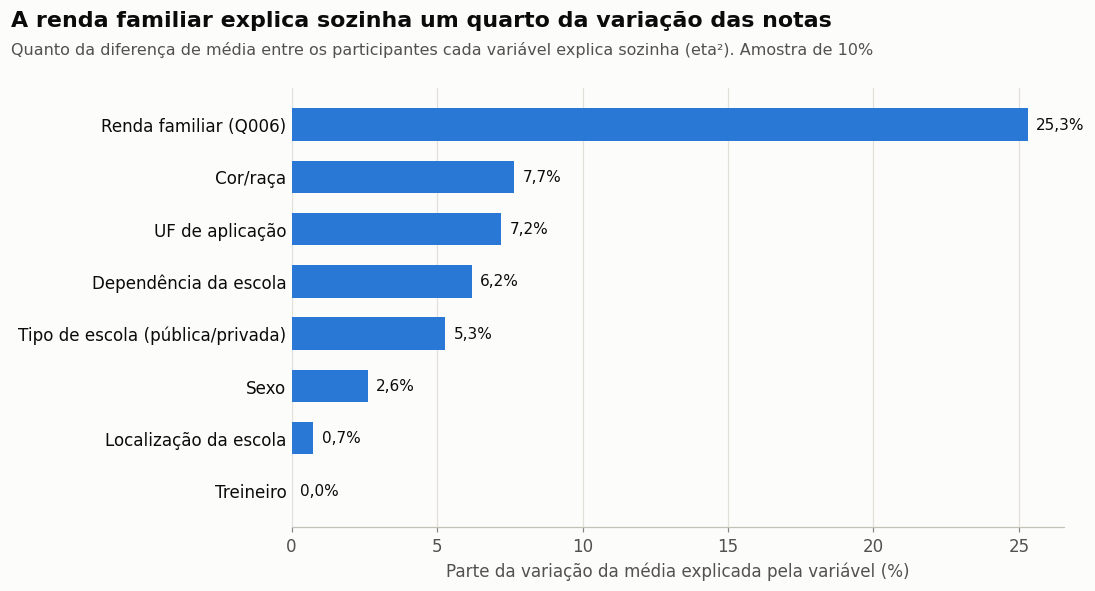

In [11]:
def eta_quadrado(grupo: pd.Series, valor: pd.Series) -> float:
    """Fração da variância de `valor` explicada pelas médias de `grupo`."""
    dados = pd.DataFrame({"g": grupo, "v": valor}).dropna()
    media_total = dados["v"].mean()
    entre = dados.groupby("g")["v"].agg(["count", "mean"])
    soma_entre = (entre["count"] * (entre["mean"] - media_total) ** 2).sum()
    soma_total = ((dados["v"] - media_total) ** 2).sum()
    return soma_entre / soma_total


categoricas = {
    "Tipo de escola (pública/privada)": amostra["ds_escola"],
    "Dependência da escola": amostra["ds_dependencia_adm_esc"],
    "UF de aplicação": amostra["sg_uf_prova"],
    "Cor/raça": amostra["ds_cor_raca"],
    "Treineiro": amostra["ds_treineiro"],
    "Sexo": amostra["ds_sexo"],
    "Localização da escola": amostra["ds_localizacao_esc"],
    "Renda familiar (Q006)": amostra["q006"],
}
eta = pd.Series({nome: eta_quadrado(serie, amostra["media"]) for nome, serie in categoricas.items()}) \
    .sort_values()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(eta.index, eta.values * 100, color=AZUL, height=0.62)
for i, valor in enumerate(eta.values):
    ax.text(valor * 100 + 0.3, i, f"{num(valor * 100)}%", va="center", fontsize=FONTE_VALOR)
ax.tick_params(axis="y", labelsize=11, labelcolor=TINTA, length=0)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Parte da variação da média explicada pela variável (%)")
salvar(fig, "06_eta_quadrado",
       "A renda familiar explica sozinha um quarto da variação das notas",
       "Quanto da diferença de média entre os participantes cada variável explica sozinha (eta²). "
       "Amostra de 10%")

## 3. Dados da redação

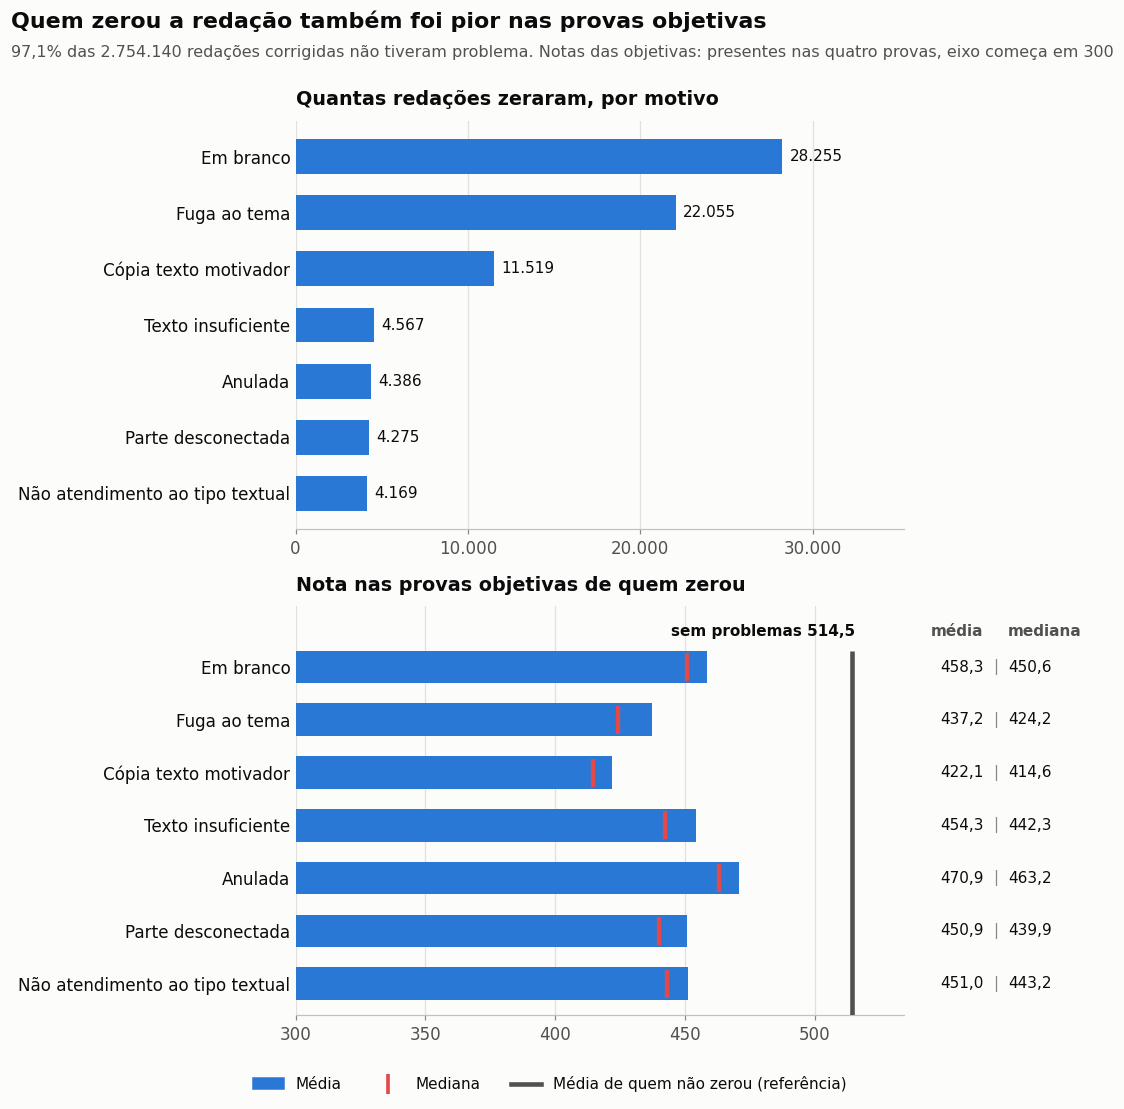

In [12]:
status = consultar("""
    SELECT s.tp_status_redacao, s.ds_status_redacao AS status, COUNT(*) AS participantes
    FROM fato_participacao f JOIN dim_status_redacao s ON s.tp_status_redacao = f.tp_status_redacao
    WHERE f.tp_status_redacao <> 0
    GROUP BY s.tp_status_redacao, s.ds_status_redacao
""")
# Média e mediana nas objetivas por situação da redação, entre os presentes nas quatro provas
objetivas_status = agregar(base, "tp_status_redacao").rename(
    columns={"media": "media_objetivas", "mediana": "mediana_objetivas", "participantes": "presentes"})
objetivas_status["tp_status_redacao"] = objetivas_status["tp_status_redacao"].astype(int)
status = status.merge(objetivas_status, on="tp_status_redacao", how="left")
total_redacoes = status["participantes"].sum()
sem_problemas = status.loc[status["status"] == "Sem problemas"].iloc[0]
problemas = status[status["status"] != "Sem problemas"].sort_values("participantes").reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9))
ax1.barh(problemas["status"], problemas["participantes"], color=AZUL, height=0.62)
for i, valor in enumerate(problemas["participantes"]):
    ax1.text(valor + 400, i, num(valor, 0), va="center", fontsize=FONTE_VALOR)
ax1.set_xlim(0, problemas["participantes"].max() * 1.25)
ax1.set_xticks([0, 10_000, 20_000, 30_000])
ax1.xaxis.set_major_formatter(lambda v, _: num(v, 0))
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_title("Quantas redações zeraram, por motivo", fontsize=12.5, pad=10)
barras_com_mediana(ax2, problemas["status"], problemas["media_objetivas"], problemas["mediana_objetivas"])
linha_referencia(ax2, sem_problemas["media_objetivas"], "sem problemas", len(problemas))
ax2.set_xlim(300, sem_problemas["media_objetivas"] + 20)
ax2.set_title("Nota nas provas objetivas de quem zerou", fontsize=12.5, pad=10)
ax1.tick_params(axis="y", labelsize=11, labelcolor=TINTA, length=0)
fig.legend(handles=LEGENDA_BARRAS + [legenda_referencia("Média de quem não zerou")], loc="upper center",
           bbox_to_anchor=(0.5, 0.0), ncols=3, fontsize=10)
salvar(fig, "07_redacao_status",
       "Quem zerou a redação também foi pior nas provas objetivas",
       f"{num(100 * sem_problemas['participantes'] / total_redacoes)}% das {num(total_redacoes, 0)} "
       "redações corrigidas não tiveram problema. Notas das objetivas: presentes nas quatro provas, "
       "eixo começa em 300")

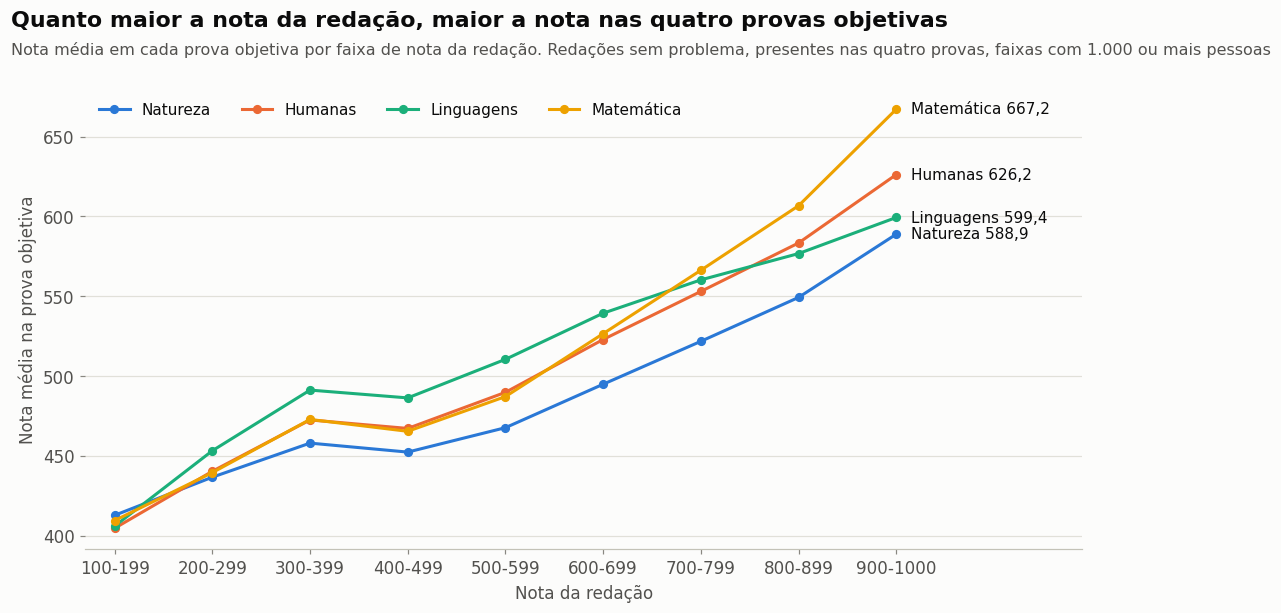

In [13]:
faixas = consultar("""
    SELECT LEAST(FLOOR(nu_nota_redacao / 100) * 100, 900) AS faixa, COUNT(*) AS participantes,
           AVG(nu_nota_cn) AS cn, AVG(nu_nota_ch) AS ch, AVG(nu_nota_lc) AS lc, AVG(nu_nota_mt) AS mt
    FROM fato_participacao
    WHERE nu_media_objetivas IS NOT NULL AND tp_status_redacao = 1
    GROUP BY faixa ORDER BY faixa
""")
faixas = faixas[faixas["participantes"] >= 1000]
fig, ax = plt.subplots(figsize=(10, 5))
for cor, (coluna, nome) in zip(SERIES, [("cn", "Natureza"), ("ch", "Humanas"), ("lc", "Linguagens"), ("mt", "Matemática")]):
    ax.plot(faixas["faixa"], faixas[coluna], color=cor, marker="o", markersize=5, label=nome)
    ax.text(faixas["faixa"].iloc[-1] + 15, faixas[coluna].iloc[-1], f"{nome} {num(faixas[coluna].iloc[-1])}",
            va="center", fontsize=FONTE_VALOR)
ax.set_xticks(faixas["faixa"], [f"{int(f)}-{int(f) + 99 if f < 900 else 1000}" for f in faixas["faixa"]])
ax.set_xlim(faixas["faixa"].min() - 30, faixas["faixa"].max() + 190)
ax.legend(loc="upper left", ncols=4, fontsize=10)
ax.set_xlabel("Nota da redação")
ax.set_ylabel("Nota média na prova objetiva")
salvar(fig, "08_objetivas_por_faixa_redacao",
       "Quanto maior a nota da redação, maior a nota nas quatro provas objetivas",
       "Nota média em cada prova objetiva por faixa de nota da redação. Redações sem problema, "
       "presentes nas quatro provas, faixas com 1.000 ou mais pessoas")

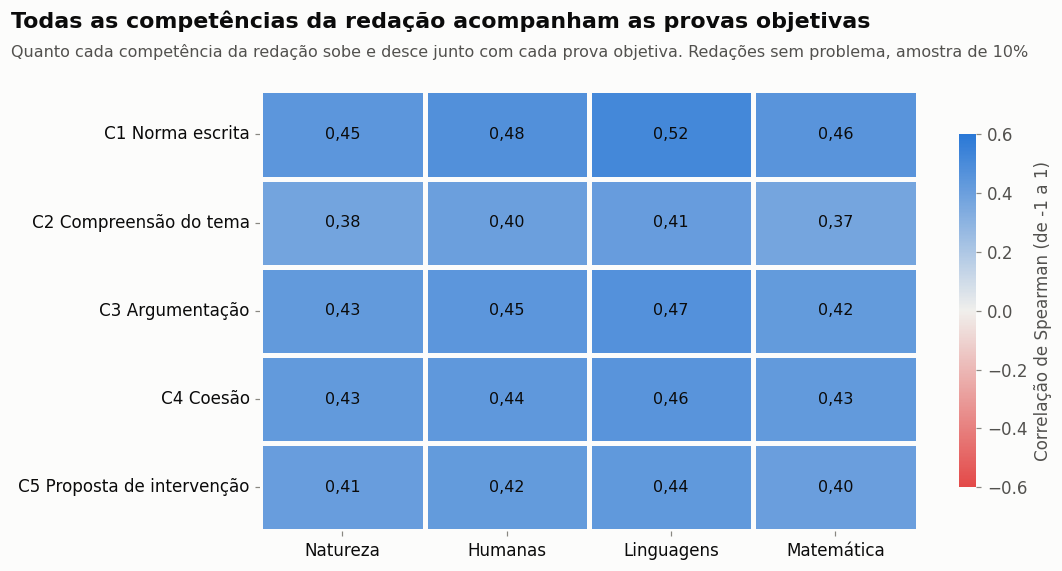

In [14]:
competencias = amostra[amostra["tp_status_redacao"] == 1][
    [f"nu_nota_comp{n}" for n in range(1, 6)] + list(PROVAS)
].corr(method="spearman").iloc[:5, 5:]
competencias.index = ["C1 Norma escrita", "C2 Compreensão do tema", "C3 Argumentação",
                      "C4 Coesão", "C5 Proposta de intervenção"]
competencias.columns = ["Natureza", "Humanas", "Linguagens", "Matemática"]
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(competencias, annot=competencias.map(lambda v: num(v, 2)), fmt="", cmap=DIVERGENTE,
            vmin=-0.6, vmax=0.6, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Spearman (de -1 a 1)", "shrink": 0.8},
            annot_kws={"fontsize": 10.5, "color": TINTA}, ax=ax)
ax.grid(False)
ax.tick_params(axis="x", labelrotation=0, labelcolor=TINTA, labelsize=11)
ax.tick_params(axis="y", labelcolor=TINTA, labelsize=11)
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "09_competencias_x_provas",
       "Todas as competências da redação acompanham as provas objetivas",
       "Quanto cada competência da redação sobe e desce junto com cada prova objetiva. "
       "Redações sem problema, amostra de 10%")

## 4. Questionário socioeconômico

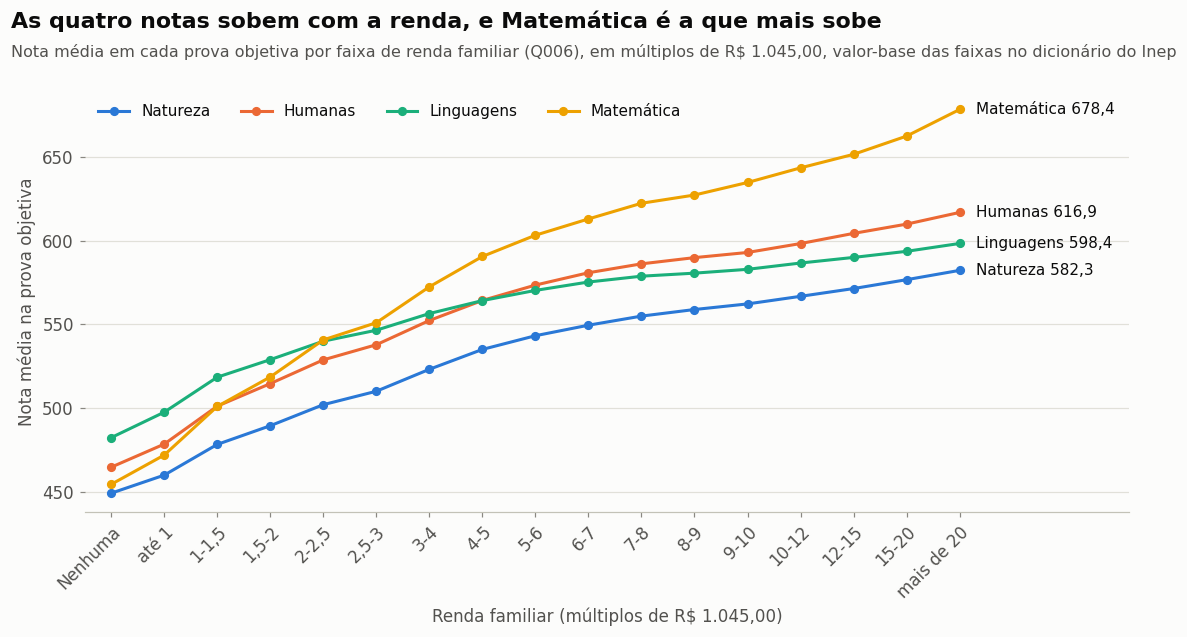

In [15]:
renda = consultar("""
    SELECT q.q006 AS faixa, COUNT(*) AS participantes,
           AVG(f.nu_nota_cn) AS cn, AVG(f.nu_nota_ch) AS ch, AVG(f.nu_nota_lc) AS lc,
           AVG(f.nu_nota_mt) AS mt, AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL AND q.q006 IS NOT NULL
    GROUP BY q.q006 ORDER BY q.q006
""")
rotulos_renda = ["Nenhuma", "até 1", "1-1,5", "1,5-2", "2-2,5", "2,5-3", "3-4", "4-5", "5-6",
                 "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15-20", "mais de 20"]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for cor, (coluna, nome) in zip(SERIES, [("cn", "Natureza"), ("ch", "Humanas"), ("lc", "Linguagens"), ("mt", "Matemática")]):
    ax.plot(range(17), renda[coluna], color=cor, marker="o", markersize=5, label=nome)
    ax.text(16.3, renda[coluna].iloc[-1], f"{nome} {num(renda[coluna].iloc[-1])}", va="center",
            fontsize=FONTE_VALOR)
ax.set_xticks(range(17), rotulos_renda)
ax.set_xlim(-0.5, 19.2)
ax.legend(loc="upper left", ncols=4, fontsize=10)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
ax.set_ylabel("Nota média na prova objetiva")
salvar(fig, "10_notas_por_renda",
       "As quatro notas sobem com a renda, e Matemática é a que mais sobe",
       "Nota média em cada prova objetiva por faixa de renda familiar (Q006), em múltiplos de "
       "R$ 1.045,00, valor-base das faixas no dicionário do Inep")

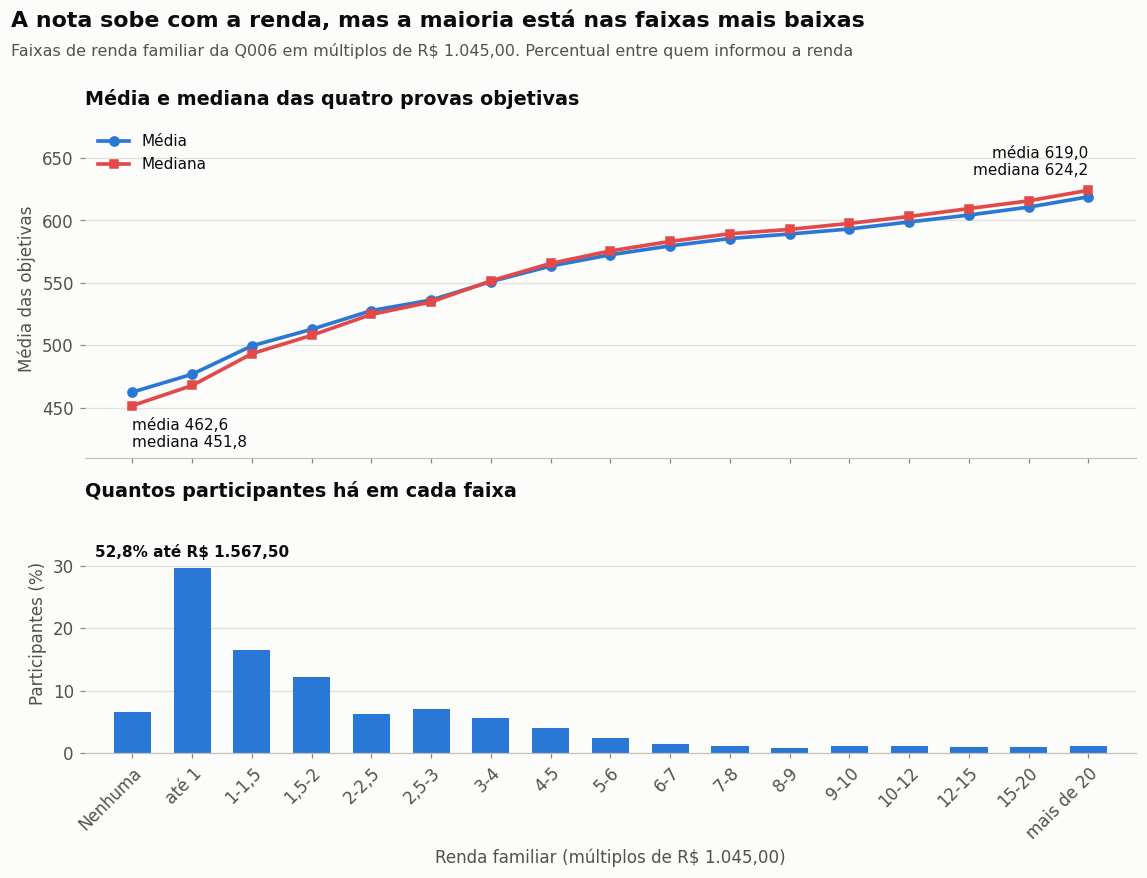

In [16]:
renda_geral = agregar(base, "q006").sort_values("q006").reset_index(drop=True)
renda_geral["pct"] = 100 * renda_geral["participantes"] / renda_geral["participantes"].sum()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 7.4), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
faixas_renda = range(len(rotulos_renda))
linha_com_mediana(ax1, faixas_renda, renda_geral["media"], renda_geral["mediana"],
                  rotulo_inicio="below", rotulo_fim="above")
ax1.legend(loc="upper left", fontsize=10)
ax1.set_xlim(-0.8, len(rotulos_renda) - 0.2)
ax1.set_ylim(410, 680)
ax1.set_ylabel("Média das objetivas")
ax1.set_title("Média e mediana das quatro provas objetivas", fontsize=12.5, pad=10)
ax2.bar(faixas_renda, renda_geral["pct"], color=AZUL, width=0.62)
ax2.set_xticks(faixas_renda, rotulos_renda)
acumulado = renda_geral["pct"].iloc[:3].sum()
ax2.text(1, renda_geral["pct"].max() * 1.06, f"{num(acumulado)}% até R$ 1.567,50", ha="center",
         fontsize=FONTE_VALOR, fontweight="bold")
ax2.set_ylim(0, renda_geral["pct"].max() * 1.3)
ax2.set_ylabel("Participantes (%)")
ax2.set_title("Quantos participantes há em cada faixa", fontsize=12.5, pad=10)
ax2.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
salvar(fig, "15_media_por_renda",
       "A nota sobe com a renda, mas a maioria está nas faixas mais baixas",
       "Faixas de renda familiar da Q006 em múltiplos de R$ 1.045,00. Percentual entre quem informou a renda")

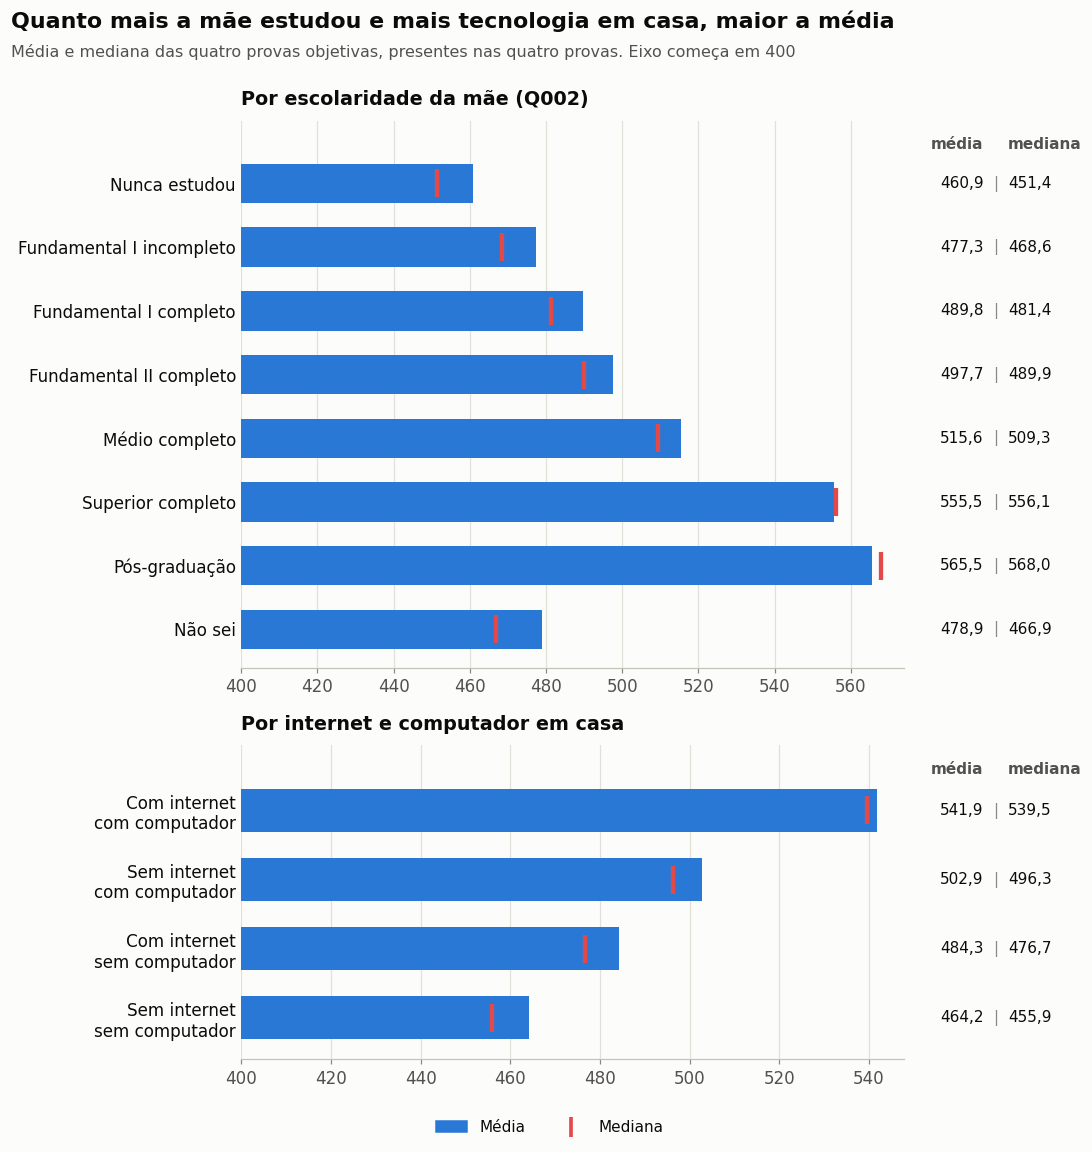

In [17]:
mae = agregar(base, "q002").rename(columns={"q002": "resposta"}).sort_values("resposta", ascending=False) \
    .reset_index(drop=True)
rotulos_mae = {"A": "Nunca estudou", "B": "Fundamental I incompleto", "C": "Fundamental I completo",
               "D": "Fundamental II completo", "E": "Médio completo", "F": "Superior completo",
               "G": "Pós-graduação", "H": "Não sei"}
com_casa = base.dropna(subset=["q024", "q025"]).assign(
    grupo=lambda d: np.where(d["q025"].astype(str) == "B", "Com internet\n", "Sem internet\n")
    + np.where(d["q024"].astype(str) > "A", "com computador", "sem computador"))
casa = agregar(com_casa, "grupo").sort_values("media").reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9.4), gridspec_kw={"height_ratios": [8, 4.6]})
barras_com_mediana(ax1, mae["resposta"].astype(str).map(rotulos_mae), mae["media"], mae["mediana"])
ax1.set_xlim(400, mae[["media", "mediana"]].max().max() + 6)
ax1.set_title("Por escolaridade da mãe (Q002)", fontsize=12.5, pad=10)
barras_com_mediana(ax2, casa["grupo"], casa["media"], casa["mediana"])
ax2.set_xlim(400, casa[["media", "mediana"]].max().max() + 6)
ax2.set_title("Por internet e computador em casa", fontsize=12.5, pad=10)
fig.legend(handles=LEGENDA_BARRAS, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncols=2, fontsize=10)
salvar(fig, "11_media_mae_internet",
       "Quanto mais a mãe estudou e mais tecnologia em casa, maior a média",
       "Média e mediana das quatro provas objetivas, presentes nas quatro provas. Eixo começa em 400")

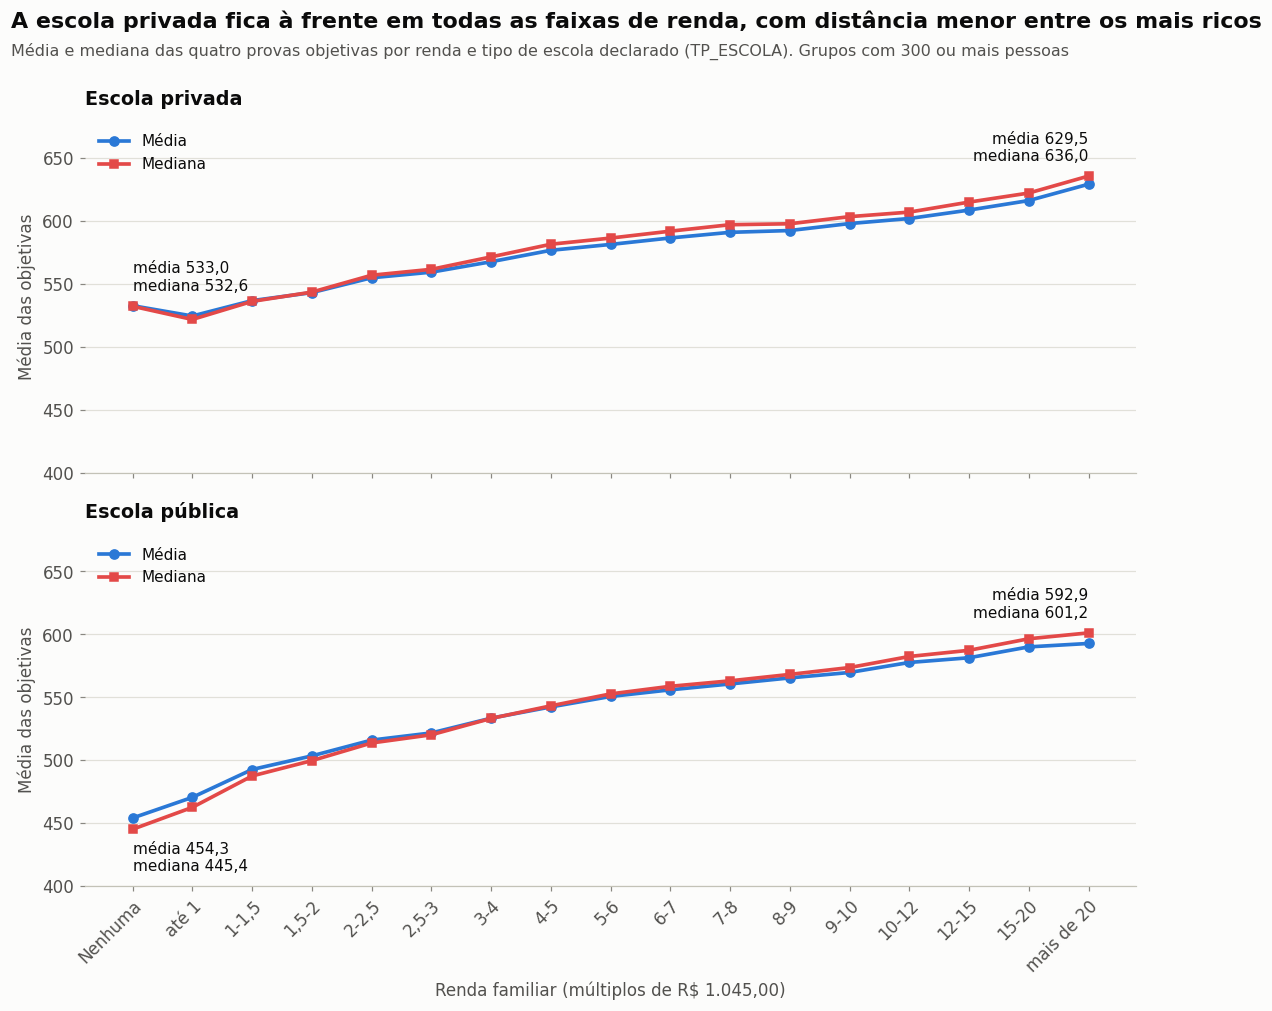

In [18]:
renda_escola = agregar(base[base["ds_escola"].isin(["Pública", "Privada"])], ["q006", "ds_escola"])
renda_escola = renda_escola[renda_escola["participantes"] >= 300]
# Um painel por tipo de escola, com o mesmo eixo vertical, para comparar a altura das linhas
fig, eixos = plt.subplots(2, 1, figsize=(10.5, 8.6), sharex=True, sharey=True)
for ax, escola, lado in zip(eixos, ["Privada", "Pública"], ["above", "below"]):
    dados = renda_escola[renda_escola["ds_escola"] == escola].sort_values("q006")
    posicoes = dados["q006"].astype(str).map({c: i for i, c in enumerate("ABCDEFGHIJKLMNOPQ")})
    linha_com_mediana(ax, posicoes, dados["media"], dados["mediana"], rotulo_inicio=lado, rotulo_fim="above")
    ax.set_title(f"Escola {escola.lower()}", fontsize=12.5, pad=10)
    ax.set_ylabel("Média das objetivas")
    ax.legend(loc="upper left", fontsize=10)
eixos[1].set_xticks(range(17), rotulos_renda)
plt.setp(eixos[1].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
eixos[1].set_xlim(-0.8, 16.8)
eixos[1].set_ylim(400, 680)
eixos[1].set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
salvar(fig, "12_renda_x_tipo_escola",
       "A escola privada fica à frente em todas as faixas de renda, com distância menor entre os mais ricos",
       "Média e mediana das quatro provas objetivas por renda e tipo de escola declarado (TP_ESCOLA). "
       "Grupos com 300 ou mais pessoas")